# Diagnóstico de atenuación de la KAN y variantes de regularización y poda

La KAN suaviza la lluvia: sus curvas tienen menos amplitud que la curva de la estación y los picos quedan por debajo. Este notebook busca de dónde viene esa atenuación y prueba variantes de la KAN para reducirla.

1. **Diagnóstico sin reentrenar**, con las predicciones de validación cruzada del notebook 01 (`Resultados_Modelos1/predicciones_vc.npz`): techo de la FPCA, puntajes FPCA y picos.
2. **Variantes de la KAN** (L1, L1 con entropía, poda con reajuste y armónicos del satélite), comparadas con la misma validación cruzada de 5 grupos de estaciones (`grupo_vc`).

Todo se calcula con las curvas de entrenamiento (1981–1997); la prueba no se usa. Se corre después del script de R y del notebook 01. Las tablas y figuras se guardan con el prefijo `10_atenuacion`.

## Configuración y datos

In [1]:
import sys
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from IPython.display import display

sys.path.append('funciones')
import Entrenamiento_red as er

datos = er.cargar_datos_red('Curvas', er.ESCALA)
meta = datos['meta']
TRAIN = datos['particion'] == 'entrenamiento'
grupos = datos['grupo_vc']
GRUPOS = er.GRUPOS_VC
assert set(grupos[TRAIN]) == set(range(1, GRUPOS + 1))

# Configuración de la KAN elegida en el notebook 01
CONFIG = pd.read_csv('Tablas/08_red_configuracion_elegida.csv').set_index('cabeza')
Q, M, LAM_RUG = int(CONFIG.loc['KAN', 'q']), int(CONFIG.loc['KAN', 'M']), float(CONFIG.loc['KAN', 'lambda'])
SEMILLAS = er.SEMILLAS

W_sat, R_sat = er.matrices_integracion(datos['t'], datos['phi_sat'])
W_est, _ = er.matrices_integracion(datos['t'], datos['phi_est'])

# Curvas de estaciones en las 72 péntadas: en la escala del modelo y en mm
phi72 = datos['phi_est'][datos['filas_pentadas']]
y_escala = datos['c_est'] @ phi72.T
Y_mm = datos['est_mm'][:, datos['filas_pentadas']]

print(f'KAN: q = {Q}, M = {M}, lambda = {LAM_RUG:g}, {er.OCULTAS_KAN or "sin"} nodos ocultos, {er.INTERVALOS_KAN} intervalos')
print('Curvas de entrenamiento por grupo:', pd.Series(grupos[TRAIN]).value_counts().sort_index().to_dict())

KAN: q = 8, M = 5, lambda = 10, sin nodos ocultos, 12 intervalos
Curvas de entrenamiento por grupo: {1.0: 433, 2.0: 412, 3.0: 419, 4.0: 378, 5.0: 316}


### Métricas por curva
Frente a la curva suavizada de la estación en las 72 péntadas:
- **RECM_mm**: raíz del error cuadrático medio.
- **razon_amplitud**: desviación estándar de la curva predicha sobre la de la estación; menor que 1 indica una curva aplanada.
- **sesgo_acumulado_pct**: diferencia porcentual del acumulado anual.
- **error_pico_1_mm / error_pico_2_mm**: máximo predicho menos máximo de la estación en marzo–junio (péntadas 13–36) y septiembre–diciembre (49–72), las mismas ventanas del notebook 04.
- **error_fecha_pico_1 / error_fecha_pico_2**: diferencia en péntadas entre la fecha de esos máximos.

In [2]:
VENTANAS_PICOS = ((13, 36), (49, 72))

def diagnostico_curvas(obs, pred):
    tabla = pd.DataFrame({
        'RECM_mm': np.sqrt(np.mean((pred - obs)**2, axis=1)),
        'razon_amplitud': pred.std(axis=1) / obs.std(axis=1),
        'sesgo_acumulado_pct': 100 * (pred.sum(axis=1) / obs.sum(axis=1) - 1),
    })
    for j, (inicio, fin) in enumerate(VENTANAS_PICOS, 1):
        ventana = slice(inicio - 1, fin)
        tabla[f'error_pico_{j}_mm'] = pred[:, ventana].max(axis=1) - obs[:, ventana].max(axis=1)
        tabla[f'error_fecha_pico_{j}'] = pred[:, ventana].argmax(axis=1) - obs[:, ventana].argmax(axis=1)
    return tabla

def resumir(tabla):
    return {'RECM_mm': tabla.RECM_mm.mean(), 'razon_amplitud': tabla.razon_amplitud.median(),
            'sesgo_acumulado_pct': tabla.sesgo_acumulado_pct.mean(),
            'error_pico_1_mm': tabla.error_pico_1_mm.mean(), 'error_pico_2_mm': tabla.error_pico_2_mm.mean(),
            'error_fecha_pico_1': tabla.error_fecha_pico_1.abs().mean(),
            'error_fecha_pico_2': tabla.error_fecha_pico_2.abs().mean()}

## 1. Diagnóstico sin reentrenar

### Techo de la FPCA
Cada curva de entrenamiento se reconstruye con sus puntajes verdaderos en las primeras M componentes de la FPCA de entrenamiento. Ese es el menor error que puede lograr el decodificador con M componentes, aunque la cabeza acierte todos los puntajes.

In [3]:
fpca = er.fit_fpca(y_escala[TRAIN], phi72.shape[1])

def reconstruir_fpca(m):
    base = fpca['base'][:m]
    return er.TRANSFORMACIONES[er.ESCALA][1](np.maximum(fpca['media'] + (y_escala - fpca['media']) @ base.T @ base, 0))

techo = []
for m in range(4, phi72.shape[1] + 1):
    techo.append({'M': m, 'varianza_explicada_pct': 100 * fpca['explicada'][:m].sum(),
                  **resumir(diagnostico_curvas(Y_mm[TRAIN], reconstruir_fpca(m)[TRAIN]))})
techo = pd.DataFrame(techo)
techo.to_csv('Tablas/10_atenuacion_techo_FPCA.csv', index=False)
techo.round(3)

,M,varianza_explicada_pct,RECM_mm,razon_amplitud,sesgo_acumulado_pct,error_pico_1_mm,error_pico_2_mm,error_fecha_pico_1,error_fecha_pico_2
0,4,91.504,3.826,0.985,-1.153,-0.434,0.831,2.963,1.030
1,5,96.012,2.591,1.020,-0.673,-0.332,1.907,2.832,0.459
2,6,100.000,1.186,1.032,-0.202,1.026,1.990,0.438,0.260


### Puntajes FPCA de la KAN
Las curvas de estación y las predicciones de validación cruzada de la KAN se proyectan sobre las mismas M componentes. Si la desviación de los puntajes predichos es menor que la de los verdaderos (razón menor que 1), la KAN encoge esa componente hacia la media.

,DE_real,DE_KAN,razon_DE,correlacion
componente,,,,
1,10.779,9.028,0.838,0.802
2,4.866,3.875,0.796,0.793
3,3.762,2.791,0.742,0.713
4,3.132,1.801,0.575,0.525
5,2.841,1.489,0.524,0.415


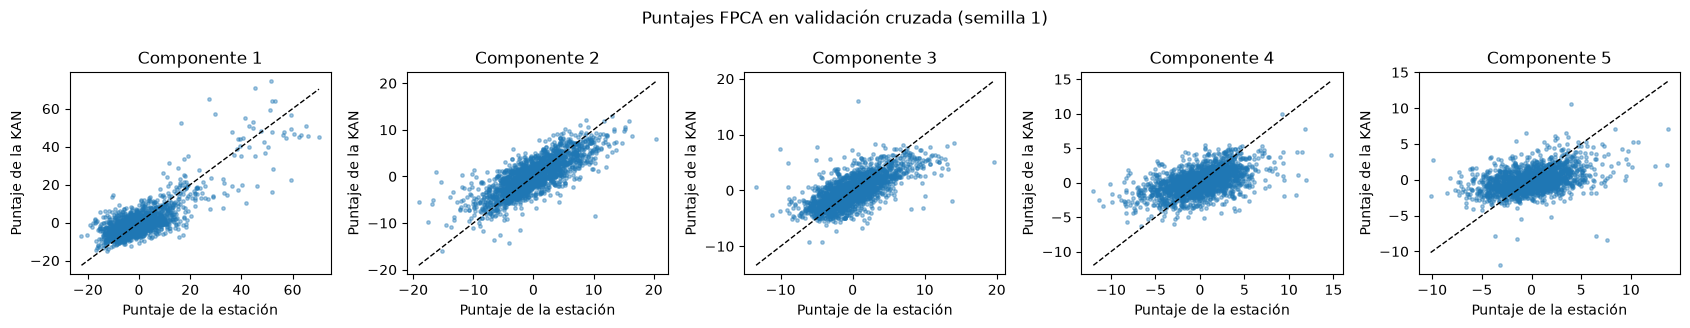

In [4]:
vc = np.load('Resultados_Modelos1/predicciones_vc.npz', allow_pickle=True)
assert (vc['curva'] == meta.curva.to_numpy()).all(), 'Las curvas no coinciden con la exportación de R.'

base_M = fpca['base'][:M]
puntajes_reales = (y_escala[TRAIN] - fpca['media']) @ base_M.T
pred_escala, pred_mm, puntajes_kan = {}, {}, {}
for s in SEMILLAS:
    c_vc = vc[f'KAN_semilla{s:04d}'][TRAIN]
    assert np.isfinite(c_vc).all()
    pred_escala[s] = c_vc @ phi72.T
    pred_mm[s] = er.TRANSFORMACIONES[er.ESCALA][1](np.maximum(pred_escala[s], 0))
    puntajes_kan[s] = (pred_escala[s] - fpca['media']) @ base_M.T

filas = []
for s in SEMILLAS:
    for j in range(M):
        real, kan = puntajes_reales[:, j], puntajes_kan[s][:, j]
        filas.append({'semilla': s, 'componente': j + 1, 'DE_real': real.std(), 'DE_KAN': kan.std(),
                      'razon_DE': kan.std() / real.std(), 'correlacion': np.corrcoef(real, kan)[0, 1]})
tabla_puntajes = pd.DataFrame(filas)
tabla_puntajes.to_csv('Tablas/10_atenuacion_puntajes.csv', index=False)
display(tabla_puntajes.groupby('componente')[['DE_real', 'DE_KAN', 'razon_DE', 'correlacion']].mean().round(3))

fig, axes = plt.subplots(1, M, figsize=(3.4 * M, 3.3))
for j, ax in enumerate(axes):
    ax.scatter(puntajes_reales[:, j], puntajes_kan[1][:, j], s=6, alpha=.4)
    lim = [puntajes_reales[:, j].min(), puntajes_reales[:, j].max()]
    ax.plot(lim, lim, 'k--', lw=1)
    ax.set(xlabel='Puntaje de la estación', ylabel='Puntaje de la KAN', title=f'Componente {j + 1}')
fig.suptitle('Puntajes FPCA en validación cruzada (semilla 1)')
fig.tight_layout(); fig.savefig('Figuras/10_atenuacion_puntajes.png', dpi=150); plt.show()

### Oráculo FPCA frente a la KAN
El oráculo es la reconstrucción con M componentes y los puntajes verdaderos. La diferencia entre el oráculo y la KAN es la parte del error que viene de la cabeza y no del decodificador. `valores_recortados_pct` es el porcentaje de péntadas predichas negativas en la escala del modelo, que se llevan a 0 antes de volver a mm.

In [5]:
oraculo = reconstruir_fpca(M)[TRAIN]
resumen = [{'modelo': 'Oráculo FPCA', 'semilla': np.nan, **resumir(diagnostico_curvas(Y_mm[TRAIN], oraculo))}]
for s in SEMILLAS:
    resumen.append({'modelo': 'KAN', 'semilla': s, **resumir(diagnostico_curvas(Y_mm[TRAIN], pred_mm[s])),
                    'valores_recortados_pct': 100 * np.mean(pred_escala[s] < 0)})
resumen = pd.DataFrame(resumen)
resumen.to_csv('Tablas/10_atenuacion_oraculo_KAN.csv', index=False)
resumen.round(3)

,modelo,semilla,RECM_mm,razon_amplitud,sesgo_acumulado_pct,error_pico_1_mm,error_pico_2_mm,error_fecha_pico_1,error_fecha_pico_2,valores_recortados_pct
0,Oráculo FPCA,NaN,2.591,1.020,-0.673,-0.332,1.907,2.832,0.459,NaN
1,KAN,1.0,9.173,0.922,5.966,-1.113,-0.128,3.565,1.631,0.054
2,KAN,2.0,9.095,0.895,3.802,-1.875,-0.891,3.418,1.557,0.074
3,KAN,3.0,9.113,0.907,4.947,-1.925,-1.162,3.416,1.593,0.031


Curvas con la mayor subestimación de cada pico y la de menor error de la KAN (semilla 1).

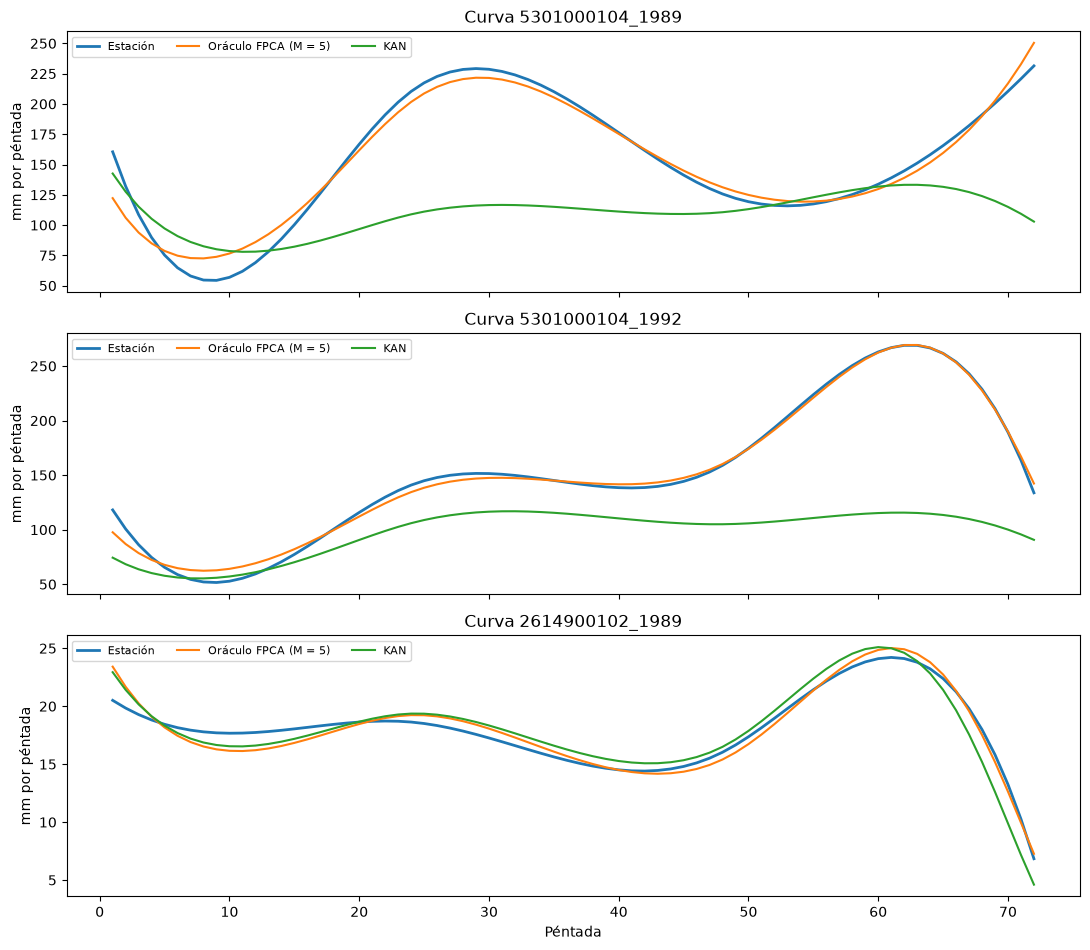

In [6]:
d1 = diagnostico_curvas(Y_mm[TRAIN], pred_mm[1])
ejemplos = list(dict.fromkeys([int(d1.error_pico_1_mm.idxmin()), int(d1.error_pico_2_mm.idxmin()), int(d1.RECM_mm.idxmin())]))
curvas_train = meta.curva.to_numpy()[TRAIN]
fig, axes = plt.subplots(len(ejemplos), 1, figsize=(11, 3.2 * len(ejemplos)), sharex=True)
for ax, i in zip(np.atleast_1d(axes), ejemplos):
    ax.plot(np.arange(1, 73), Y_mm[TRAIN][i], lw=2, label='Estación')
    ax.plot(np.arange(1, 73), oraculo[i], lw=1.5, label=f'Oráculo FPCA (M = {M})')
    ax.plot(np.arange(1, 73), pred_mm[1][i], lw=1.5, label='KAN')
    ax.set(ylabel='mm por péntada', title=f'Curva {curvas_train[i]}')
    ax.legend(ncol=3, fontsize=8)
np.atleast_1d(axes)[-1].set_xlabel('Péntada')
fig.tight_layout(); fig.savefig('Figuras/10_atenuacion_curvas.png', dpi=150); plt.show()

## 2. Variantes de la KAN

Todas usan la configuración elegida en el notebook 01 (q, M, λ, nodos e intervalos) y se comparan con la misma validación cruzada.

| Variante | Qué cambia |
| --- | --- |
| `original` | KAN sin cambios, una fase de entrenamiento |
| `l1` | Penalización L1 de la importancia de las aristas |
| `l1_entropia` | L1 más la entropía de la importancia de las aristas, que favorece pocas aristas importantes |
| `control_reajuste` | Primera fase y una segunda fase de reajuste, sin podar |
| `poda` | Igual que el control, pero antes del reajuste se anula el 20 % de aristas con menor importancia en cada capa |
| `armonicos` | Agrega a la cabeza 4 entradas: la proyección de la curva del satélite sobre senos y cosenos anual y semestral |

El efecto de podar se mide con `poda` frente a `control_reajuste`: tienen la misma semilla, grupo y número de épocas, y solo difieren en las aristas anuladas. La variante `armonicos` tiene más entradas y parámetros que las demás.

In [7]:
# Capa KAN que separa la contribución de cada arista y permite anular aristas con una máscara
class CapaKANPodable(er.CapaKAN):
    def __init__(self, entradas, salidas, intervalos=er.INTERVALOS_KAN):
        super().__init__(entradas, salidas, intervalos)
        self.register_buffer('mascara_aristas', torch.ones(salidas, entradas, dtype=torch.float64))

    def contribuciones(self, x):
        normalizada = (x - self.centro) / self.escala
        base = nn.functional.silu(normalizada).unsqueeze(1) * self.peso_base.unsqueeze(0)
        coeficientes = self.peso_spline.unsqueeze(-1) * self.coeficientes
        return base + torch.einsum('big,oig->boi', self.bases(normalizada), coeficientes)

    def forward(self, x):
        return (self.contribuciones(x) * self.mascara_aristas).sum(dim=2)

    # Importancia de cada arista: valor absoluto medio de su contribución
    def importancia(self, x):
        return (self.contribuciones(x) * self.mascara_aristas).abs().mean(dim=0)


# Codificador funcional y cabeza KAN con capas podables (la misma arquitectura del proyecto); con armonicos=True se agregan 4 entradas
class KANExperimental(nn.Module):
    def __init__(self, armonicos=False):
        super().__init__()
        self.codificador = er.CodificadorFuncional(W_sat, Q, R_sat)
        self.armonicos = armonicos
        extra = 4 if armonicos else 0
        tamanos = [Q + 2 + extra] + ([er.OCULTAS_KAN] if er.OCULTAS_KAN else []) + [M]
        self.cabeza = nn.ModuleList([CapaKANPodable(a, b) for a, b in zip(tamanos[:-1], tamanos[1:])])
        # Integral de cada función base del satélite por sen y cos de periodo anual y semestral
        t = datos['t']
        u = (t - t[0]) / (t[-1] - t[0])
        ondas = np.stack([np.sin(2 * np.pi * u), np.cos(2 * np.pi * u), np.sin(4 * np.pi * u), np.cos(4 * np.pi * u)], axis=1)
        proyeccion = np.trapezoid(datos['phi_sat'][:, :, None] * ondas[:, None, :], t, axis=0) / (t[-1] - t[0])
        self.register_buffer('pesos_armonicos', torch.as_tensor(proyeccion, dtype=torch.float64))
        self.register_buffer('media_armonicos', torch.zeros(4, dtype=torch.float64))
        self.register_buffer('desviacion_armonicos', torch.ones(4, dtype=torch.float64))

    def entradas(self, c, cov):
        z = self.codificador(c, cov)
        if self.armonicos:
            z = torch.cat([z, (c @ self.pesos_armonicos - self.media_armonicos) / self.desviacion_armonicos], dim=1)
        return z

    def forward(self, c, cov):
        h = self.entradas(c, cov)
        for capa in self.cabeza: h = capa(h)
        return h

    # Escalas de las entradas de cada capa, calculadas con las curvas de ajuste
    @torch.no_grad()
    def calibrar(self, c, cov):
        if self.armonicos:
            a = c @ self.pesos_armonicos
            self.media_armonicos.copy_(a.mean(0)); self.desviacion_armonicos.copy_(a.std(0, unbiased=False).clamp_min(1e-8))
        h = self.entradas(c, cov)
        for capa in self.cabeza:
            capa.calibrar(h); h = capa(h)

    # L1: suma de las importancias; entropía de la importancia normalizada de las aristas de cada capa
    def penalizaciones(self, c, cov):
        h = self.entradas(c, cov)
        l1, entropia = h.new_zeros(()), h.new_zeros(())
        for capa in self.cabeza:
            imp = capa.importancia(h)
            p = imp / (imp.sum() + 1e-12)
            l1 = l1 + imp.sum()
            entropia = entropia - (p * torch.log(p.clamp_min(1e-12))).sum()
            h = capa(h)
        return l1, entropia

    # Anula en cada capa la fracción de aristas con menor importancia
    @torch.no_grad()
    def podar(self, c, cov, fraccion):
        h = self.entradas(c, cov)
        anuladas = 0
        for capa in self.cabeza:
            importancia = capa.importancia(h).flatten()
            mascara = torch.ones_like(importancia)
            mascara[torch.argsort(importancia)[:int(fraccion * importancia.numel())]] = 0
            capa.mascara_aristas.copy_(mascara.view_as(capa.mascara_aristas))
            anuladas += int((mascara == 0).sum())
            h = capa(h)
        return anuladas


# Sin máscara, la capa podable da lo mismo que la capa KAN del proyecto
torch.manual_seed(2026)
x = torch.randn(7, Q + 2, dtype=torch.float64)
capa, podable = er.CapaKAN(Q + 2, 4), CapaKANPodable(Q + 2, 4)
podable.load_state_dict(capa.state_dict(), strict=False)
assert torch.allclose(capa(x), podable(x), atol=1e-10)

### Entrenamiento de una variante en un grupo
En cada grupo, la estandarización de las covariables, la FPCA y la calibración de la KAN se calculan solo con las curvas de ajuste. La parada temprana usa el grupo que queda fuera, como en el notebook 01. Los pesos de L1 y de la entropía se fijan antes de entrenar, como una fracción de la pérdida inicial de ajuste. El reajuste del control y de la poda parte del mejor estado de la primera fase y dura un tercio de las épocas (mínimo 50).

In [8]:
EPOCAS = er.EPOCAS_MAXIMAS
PACIENCIA = er.PACIENCIA
FRACCION_PODA = 0.20
FRACCION_L1 = 0.01
FRACCION_ENTROPIA = 0.005
VARIANTES = ('original', 'l1', 'l1_entropia', 'control_reajuste', 'poda', 'armonicos')
T = lambda a: torch.as_tensor(a, dtype=torch.float64)

def entrenar_variante(ajuste, validacion, semilla, variante, epocas=EPOCAS, paciencia=PACIENCIA):
    er.establecer_semilla(semilla)
    cov_norm = er.NormalizadorCovariables().ajustar(datos['cov'], ajuste).transformar(datos['cov'])
    _, mu_c, psi_c, _ = er.preparar_fpca(datos, M, ajuste)
    modelo = KANExperimental(armonicos=(variante == 'armonicos'))
    c_tr, h_tr, y_tr = T(datos['c_sat'][ajuste]), T(cov_norm[ajuste]), T(datos['c_est'][ajuste])
    c_va, h_va, y_va = T(datos['c_sat'][validacion]), T(cov_norm[validacion]), T(datos['c_est'][validacion])
    modelo.calibrar(c_tr, h_tr)
    perdida = er.PerdidaFuncional(W_est, mu_c, psi_c, LAM_RUG)

    with torch.no_grad():
        error_inicial = perdida.error_l2(modelo(c_tr, h_tr), y_tr).item()
        l1_inicial, entropia_inicial = modelo.penalizaciones(c_tr, h_tr)
    peso_l1 = FRACCION_L1 * error_inicial / max(l1_inicial.item(), 1e-12) if variante in ('l1', 'l1_entropia') else 0.0
    peso_entropia = FRACCION_ENTROPIA * error_inicial / max(entropia_inicial.item(), 1e-12) if variante == 'l1_entropia' else 0.0

    def fase(n_epocas):
        optimizador = torch.optim.AdamW(modelo.parameters(), lr=er.TASA_APRENDIZAJE, weight_decay=0)
        mejor, mejor_epoca, estado, sin_mejora = np.inf, 0, None, 0
        for epoca in range(1, n_epocas + 1):
            modelo.train(); optimizador.zero_grad(set_to_none=True)
            objetivo = perdida(modelo(c_tr, h_tr), y_tr, modelo.codificador)
            if peso_l1 or peso_entropia:
                l1, entropia = modelo.penalizaciones(c_tr, h_tr)
                objetivo = objetivo + peso_l1 * l1 + peso_entropia * entropia
            objetivo.backward()
            # Las aristas anuladas no se actualizan
            for capa in modelo.cabeza:
                capa.peso_base.grad.mul_(capa.mascara_aristas)
                capa.peso_spline.grad.mul_(capa.mascara_aristas)
                capa.coeficientes.grad.mul_(capa.mascara_aristas.unsqueeze(-1))
            optimizador.step(); modelo.eval()
            with torch.no_grad(): valor = perdida.error_l2(modelo(c_va, h_va), y_va).item()
            if valor < mejor - 1e-10:
                mejor, mejor_epoca, estado, sin_mejora = valor, epoca, copy.deepcopy(modelo.state_dict()), 0
            else:
                sin_mejora += 1
                if sin_mejora >= paciencia: break
        modelo.load_state_dict(estado)
        return mejor, mejor_epoca

    mejor, mejor_epoca = fase(epocas)
    anuladas = 0
    if variante in ('control_reajuste', 'poda'):
        if variante == 'poda': anuladas = modelo.podar(c_tr, h_tr, FRACCION_PODA)
        mejor, mejor_epoca = fase(max(50, epocas // 3))
    with torch.no_grad():
        c_hat = perdida.coeficientes(modelo(c_va, h_va)).numpy()
    pred = er.reconstruir_mm(c_hat, datos['phi_est'], er.ESCALA)[0][:, datos['filas_pentadas']]
    return pred, {'L2_validacion': mejor, 'mejor_epoca': mejor_epoca, 'aristas_anuladas': anuladas,
                  'peso_L1': peso_l1, 'peso_entropia': peso_entropia}

### Validación cruzada de las variantes
5 grupos × 3 semillas × 6 variantes. Las métricas de cada grupo se calculan con las curvas que quedan fuera.

In [9]:
filas = []
for grupo in range(1, GRUPOS + 1):
    ajuste, validacion = TRAIN & (grupos != grupo), TRAIN & (grupos == grupo)
    for semilla in SEMILLAS:
        for variante in VARIANTES:
            pred, info = entrenar_variante(ajuste, validacion, semilla, variante)
            metricas = resumir(diagnostico_curvas(Y_mm[validacion], pred))
            filas.append({'grupo': grupo, 'semilla': semilla, 'variante': variante, 'curvas': int(validacion.sum()),
                          **info, **metricas})
            print(f'grupo {grupo}, semilla {semilla}, {variante}: RECM = {metricas["RECM_mm"]:.3f} mm, '
                  f'amplitud = {metricas["razon_amplitud"]:.3f}', flush=True)
variantes_vc = pd.DataFrame(filas)
variantes_vc.to_csv('Tablas/10_atenuacion_variantes_vc.csv', index=False)

grupo 1, semilla 1, original: RECM = 10.732 mm, amplitud = 0.885
grupo 1, semilla 1, l1: RECM = 10.762 mm, amplitud = 0.871
grupo 1, semilla 1, l1_entropia: RECM = 10.697 mm, amplitud = 0.854
grupo 1, semilla 1, control_reajuste: RECM = 10.469 mm, amplitud = 0.885
grupo 1, semilla 1, poda: RECM = 10.729 mm, amplitud = 0.907
grupo 1, semilla 1, armonicos: RECM = 10.617 mm, amplitud = 0.901
grupo 1, semilla 2, original: RECM = 10.477 mm, amplitud = 0.883
grupo 1, semilla 2, l1: RECM = 10.478 mm, amplitud = 0.882
grupo 1, semilla 2, l1_entropia: RECM = 10.512 mm, amplitud = 0.894
grupo 1, semilla 2, control_reajuste: RECM = 10.349 mm, amplitud = 0.890
grupo 1, semilla 2, poda: RECM = 10.473 mm, amplitud = 0.886
grupo 1, semilla 2, armonicos: RECM = 10.550 mm, amplitud = 0.894
grupo 1, semilla 3, original: RECM = 10.661 mm, amplitud = 0.926
grupo 1, semilla 3, l1: RECM = 10.771 mm, amplitud = 0.918
grupo 1, semilla 3, l1_entropia: RECM = 10.784 mm, amplitud = 0.916
grupo 1, semilla 3, cont

### Resumen y poda frente al control
Media de los 5 grupos y las 3 semillas. En la comparación pareada (mismo grupo y semilla), una diferencia de RECM negativa favorece la poda; en la amplitud interesa acercarse a 1.

,RECM_mm,RECM_desv,razon_amplitud,error_pico_1_mm,error_pico_2_mm,L2_validacion
variante,,,,,,
original,9.097,1.054,0.909,-1.579,-0.653,78.791
l1,9.087,1.053,0.896,-1.705,-0.719,78.810
l1_entropia,9.084,1.044,0.898,-1.629,-0.631,78.743
control_reajuste,9.074,0.985,0.912,-1.758,-0.490,78.163
poda,9.119,1.042,0.905,-1.914,-0.914,78.880
armonicos,9.110,0.999,0.913,-1.483,-0.391,78.846


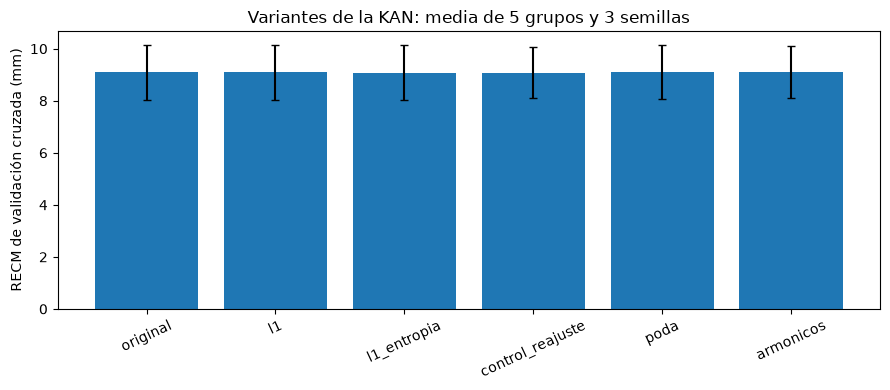

RECM_mm_poda  L2_validacion_poda  razon_amplitud_poda  \
grupo semilla                                                          
1     1              10.729              97.193                0.907   
      2              10.473              96.478                0.886   
      3              10.453              94.470                0.924   
2     1               8.859              75.920                0.883   
      2               9.260              82.505                0.835   
      3               8.899              77.791                0.851   
3     1               9.103              76.459                0.869   
      2               9.229              78.841                0.855   
      3               8.991              76.119                0.906   
4     1               7.473              59.446                0.986   
      2               7.461              59.191                0.958   
      3               7.417              62.105                0.898   
5     1               9.317              79.457                0.934   
      2               9.700              85.211                0.924   
      3               9.421              82.011                0.953   

               RECM_mm_control  L2_validacion_control  razon_amplitud_control  \
grupo semilla                                                                   
1     1                 10.469                 94.172                   0.885   
      2                 10.349                 94.449                   0.890   
      3                 10.447                 95.304                   0.919   
2     1                  8.899                 76.807                   0.858   
      2                  8.733                 73.522                   0.918   
      3                  9.018                 78.887                   0.896   
3     1                  9.308                 79.929                   0.863   
      2                  9.218                 79.184                   0.862   
      3                  8.940                 75.732                   0.886   
4     1                  7.397                 58.433                   0.983   
      2                  7.422                 58.998                   0.990   
      3                  7.662                 61.524                   1.015   
5     1                  9.382                 80.285                   0.933   
      2                  9.453                 82.924                   0.858   
      3                  9.420                 82.297                   0.919   

               dif_RECM_mm  dif_L2  mejora_amplitud  
grupo semilla                                        
1     1              0.259   3.021            0.022  
      2              0.124   2.029           -0.004  
      3              0.006  -0.835            0.006  
2     1             -0.040  -0.887            0.025  
      2              0.527   8.983           -0.083  
      3             -0.119  -1.096           -0.046  
3     1             -0.205  -3.471            0.006  
      2              0.011  -0.343           -0.007  
      3              0.051   0.387            0.020  
4     1              0.076   1.013            0.003  
      2              0.039   0.192           -0.032  
      3             -0.246   0.580           -0.087  
5     1             -0.065  -0.828            0.001  
      2              0.248   2.287            0.065  
      3              0.002  -0.286            0.034

Diferencia media de RECM (poda - control): 0.044 mm; grupos y semillas en que la poda gana: 5 de 15


In [10]:
resumen_variantes = variantes_vc.groupby('variante').agg(
    RECM_mm=('RECM_mm', 'mean'), RECM_desv=('RECM_mm', 'std'), razon_amplitud=('razon_amplitud', 'mean'),
    error_pico_1_mm=('error_pico_1_mm', 'mean'), error_pico_2_mm=('error_pico_2_mm', 'mean'),
    L2_validacion=('L2_validacion', 'mean')).loc[list(VARIANTES)]
resumen_variantes.to_csv('Tablas/10_atenuacion_variantes_resumen.csv')
display(resumen_variantes.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(resumen_variantes.index, resumen_variantes.RECM_mm, yerr=resumen_variantes.RECM_desv, capsize=3)
ax.set(ylabel='RECM de validación cruzada (mm)', title='Variantes de la KAN: media de 5 grupos y 3 semillas')
ax.tick_params(axis='x', rotation=25)
fig.tight_layout(); fig.savefig('Figuras/10_atenuacion_variantes_RECM.png', dpi=150); plt.show()

columnas = ['RECM_mm', 'L2_validacion', 'razon_amplitud']
poda = variantes_vc[variantes_vc.variante == 'poda'].set_index(['grupo', 'semilla'])[columnas]
control = variantes_vc[variantes_vc.variante == 'control_reajuste'].set_index(['grupo', 'semilla'])[columnas]
pares = poda.add_suffix('_poda').join(control.add_suffix('_control'))
pares['dif_RECM_mm'] = pares.RECM_mm_poda - pares.RECM_mm_control
pares['dif_L2'] = pares.L2_validacion_poda - pares.L2_validacion_control
pares['mejora_amplitud'] = (pares.razon_amplitud_control - 1).abs() - (pares.razon_amplitud_poda - 1).abs()
pares.to_csv('Tablas/10_atenuacion_poda_vs_control.csv')
display(pares.round(3))
print('Diferencia media de RECM (poda - control):', round(pares.dif_RECM_mm.mean(), 3), 'mm;',
      'grupos y semillas en que la poda gana:', int((pares.dif_RECM_mm < 0).sum()), 'de', len(pares))

## Cómo leer los resultados
- **Techo de la FPCA:** si el oráculo con M componentes ya tiene poca amplitud o subestima los picos, parte de la atenuación viene del decodificador y no de la cabeza.
- **Puntajes:** una razón de desviaciones menor que 1 en una componente indica que la KAN la encoge hacia la media; una correlación baja indica que no aprende esa componente.
- **Poda:** solo la comparación `poda − control_reajuste` atribuye la diferencia a anular aristas; frente a `original`, la poda también tiene más épocas.
- **L1 y entropía:** se comparan con `original`, porque tienen una sola fase.
- **Armónicos:** cambian las entradas y el número de parámetros, así que no son una comparación con los parámetros igualados.
- Ninguna variante se elige con la prueba. Si una se adopta, se reentrena en el notebook 01 y se evalúa en el 04.